# A cascade of pretrained YOLO models on a photographic collection: the Fonds Thierry

Computer Vision & Heritage, session 1 (AI for heritage, images as matrices), hands-on at the end of part 2

Goal: what generic, supervised models (COCO and ADE20K: closed vocabularies; depth) tell an institution about a collection, step after step.

Images: INHA, Fonds Nicole et Jean-Michel Thierry, licence CC BY-NC-ND 4.0. ND: do not share the derived images you make (crop, mask, cut-out, annotated or blurred image, gallery).

In [1]:
import os
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from PIL import Image, ImageDraw, ImageFilter, ImageStat
from ultralytics import YOLO

## 0. Paths and models

In [2]:
# The 8 scans
DATASET = os.path.join("..", "datasets", "dataset-s01-tp")

In [3]:
# Polars tables: up to 20 rows shown, strings up to 50 characters
pl.Config.set_tbl_rows(20).set_fmt_str_lengths(50)
# Tables written by the notebook (data/: not versioned)
OUT = os.path.join(DATASET, "..", "..", "data", "thierry")
os.makedirs(OUT, exist_ok=True)

In [4]:
# The four models; first run: each downloads its weights into this folder
# Object detection, COCO, 80 classes (5.5 MB)
det_model = YOLO("yolo26n.pt")
# Instance segmentation, COCO, 80 classes: a box and a mask per object (6.7 MB)
seg_model = YOLO("yolo26n-seg.pt")
# Semantic segmentation, ADE20K, 150 classes: a class per pixel (3.5 MB)
sem_model = YOLO("yolo26n-sem-ade20k.pt")
# Depth estimation: a distance per pixel, in metres (13 MB)
depth_model = YOLO("yolo26n-depth.pt")

## 1. The collection

List the `.jpg` files of `DATASET`, in alphabetical order: `files` (`os.listdir`, `sorted`).

In [5]:
# --- 1. The collection ---
# The scans of the folder, in alphabetical order
files = sorted(f for f in os.listdir(DATASET) if f.endswith(".jpg"))

Give each slide a short name, `slides`: the file name without the beginning shared by all the files (`os.path.commonprefix`) and without the extension (`removeprefix`, `removesuffix`).

In [6]:
# A short name per slide: the file name without the beginning shared by all the files and the extension
slides = [f.removeprefix(os.path.commonprefix(files)).removesuffix(".jpg") for f in files]

Display `slides`.

In [7]:
slides

['bureauJMT_20_65_000004',
 'bureauJMT_22_1_1_000002',
 'bureauJMT_22_1_1_000006',
 'bureauJMT_22_1_1_000007',
 'salon_20_13_13_000002',
 'salon_20_13_19_000004',
 'salon_20_13_19_000005',
 'salon_20_13_19_000008']

Show the 8 scans in a grid of 2 × 4 axes (`plt.subplots`), each titled with its short name, without axes: four 35 mm slides in their mounts, four medium-format films with their black edges.

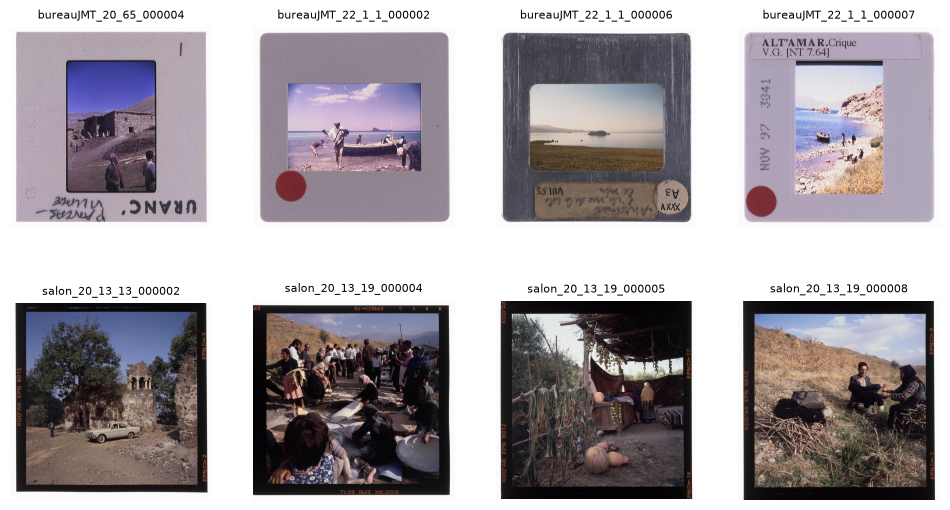

In [8]:
# The 8 scans: four 35 mm slides in their mounts, four medium-format films with their black edges
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, f, slide in zip(axes.flat, files, slides):
    ax.imshow(Image.open(os.path.join(DATASET, f)))
    ax.set_title(slide, fontsize=8)
    ax.axis("off")
plt.show()

Open the first scan (`Image.open`): `village`, a 35 mm slide in its mount, captioned "URANC' village".

In [9]:
# The first one: a 35 mm slide in its mount, captioned "URANC' village"
village = Image.open(os.path.join(DATASET, files[0]))

Print `village`: its class, mode and size (printed, so that the 15-megapixel scan is not embedded in the notebook).

In [10]:
# The PIL object: its class, mode and size (printed, so that the 15-megapixel scan is not embedded in the notebook)
print(village)

<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=3917x3880 at 0x11D23B680>


Display its size: PIL gives (width, height).

In [11]:
# PIL: (width, height)
village.size

(3917, 3880)

Display its mode.

In [12]:
# Three channels: red, green, blue
village.mode

'RGB'

Display the shape of the same image as a NumPy array (`np.asarray`): (height, width, channels), rows first.

In [13]:
# NumPy: (height, width, channels), rows first
np.asarray(village).shape

(3880, 3917, 3)

## 2. Remove the mount, without a model

Strategy: (1) the colour of the mount, measured near the four corners; (2) threshold: the pixels close to this colour; (3) keep the zone: the columns, then the rows, where such pixels are less than half.

Convert `village` to a NumPy array of integers (`astype(int)`): `arr`, of shape (H, W, 3).

In [14]:
# --- 2. Remove the mount, without a model ---
# Strategy: (1) the colour of the mount, measured near the four corners; (2) threshold: the pixels close to this
# colour; (3) keep the zone: the columns, then the rows, where such pixels are less than half
# The scan as an array of integers: (H, W, 3)
arr = np.asarray(village).astype(int)

(1) Write `mount_colour(arr)`: the median (R, G, B) of the pixels of four square patches near the corners, from `p0 = int(0.04 * min(W, H))` to `p1 = int(0.12 * min(W, H))` pixels from each corner (the patches reshaped to (N, 3), concatenated, then `np.median` along axis 0).

In [15]:
# (1) Colour of the mount: median of the pixels of four patches near the corners (from 4 % to 12 % of the shorter side)
def mount_colour(arr):
    H, W = arr.shape[:2]
    p0, p1 = int(0.04 * min(W, H)), int(0.12 * min(W, H))
    patches = [arr[p0:p1, p0:p1], arr[p0:p1, -p1:-p0], arr[-p1:-p0, p0:p1], arr[-p1:-p0, -p1:-p0]]
    return np.median(np.concatenate([q.reshape(-1, 3) for q in patches]), axis=0)

Apply it to `arr`: `mount`.

In [16]:
mount = mount_colour(arr)

Display `mount`.

In [17]:
mount

array([        180,         168,         179])

(2) Threshold: compute `like_mount`, True where the sum over R, G, B of the absolute differences between the pixel and `mount` is under 25.

In [18]:
# (2) Threshold: a pixel is like the mount when the sum of its differences to this colour (R, G, B) is under 25
like_mount = np.abs(arr - mount).sum(axis=2) < 25

Display its shape: one boolean per pixel, (H, W).

In [19]:
# One boolean per pixel: (H, W)
like_mount.shape

(3880, 3917)

Show `like_mount` as an image (`plt.imshow`, `cmap="gray"`): the pixels like the mount in white.

In [20]:
# Derived image: the pixels like the mount (white)
plt.figure(figsize=(4.5, 4.5))
plt.imshow(like_mount, cmap="gray")
plt.show()

(3) Compute the share of the pixels like the mount in each column (x): `column_share`.

In [21]:
# (3) Share of the pixels like the mount, in each column (x)
column_share = like_mount.mean(axis=0)

… and in each row (y): `row_share`.

In [22]:
# ... and in each row (y)
row_share = like_mount.mean(axis=1)

Plot `column_share` and `row_share` side by side, each with a horizontal line at 0.5 (`axhline`): the columns and the rows of the photo are under 0.5.

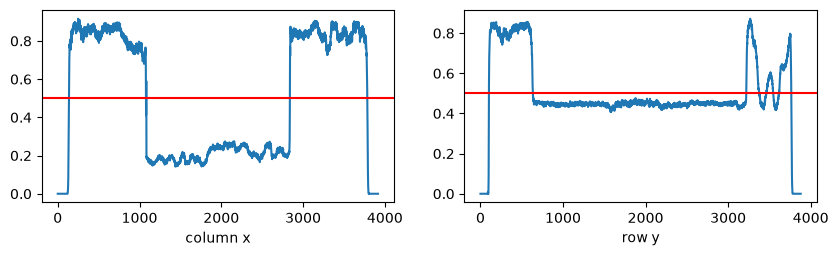

In [23]:
# The columns and the rows of the photo are under 0.5
fig, axes = plt.subplots(1, 2, figsize=(10, 2.5))
axes[0].plot(column_share)
axes[0].axhline(0.5, color="red")
axes[0].set_xlabel("column x")
axes[1].plot(row_share)
axes[1].axhline(0.5, color="red")
axes[1].set_xlabel("row y")
plt.show()

Write `longest_run(flags)`: `(start, end)` of the longest run of consecutive `True` in a sequence of booleans, `end` excluded. Then `keep_zone(like_mount, share=0.5, passes=3)`: start from all the rows (`y1, y2 = 0, H`) and, `passes` times, take as columns `x1, x2` the longest run of columns whose share over the rows `y1:y2` is under `share`, then as rows `y1, y2` the longest run of rows whose share over the columns `x1:x2` is under `share`; it returns `(x1, y1, x2, y2)`.

In [24]:
# Keep the zone: the longest run of columns under 0.5; inside these columns, the longest run of rows under 0.5;
# three times, each pass inside the zone of the previous one
def longest_run(flags):
    best, start, run_start = 0, 0, None
    for k, flag in enumerate(list(flags) + [False]):
        if flag and run_start is None:
            run_start = k
        elif not flag and run_start is not None:
            if k - run_start > best:
                best, start = k - run_start, run_start
            run_start = None
    return start, start + best


def keep_zone(like_mount, share=0.5, passes=3):
    H, W = like_mount.shape
    y1, y2 = 0, H
    for _ in range(passes):
        x1, x2 = longest_run(like_mount[y1:y2].mean(axis=0) < share)
        y1, y2 = longest_run(like_mount[:, x1:x2].mean(axis=1) < share)
    return x1, y1, x2, y2

Apply it to `like_mount`: `box`, the zone kept, (x1, y1, x2, y2) in pixels of the scan.

In [25]:
# The zone kept: (x1, y1, x2, y2) in pixels of the scan
box = keep_zone(like_mount)

Display `box`.

In [26]:
box

(1084, 626, 2840, 3225)

Write `frame_box(scan)`, the whole strategy for any scan (threshold 25, share 0.5; both set on these 8 scans: check the frames found), and the format from the shape of the zone, `ratio = (x2 - x1) / (y2 - y1)`: `"film"` if 0.85 < ratio < 1.15 (square, medium-format 6 × 6), else `"35mm-portrait"` if ratio < 1, else `"35mm-landscape"` (2:3, 35 mm slide). It returns `(format, (x1, y1, x2, y2))`.

In [27]:
# The whole strategy, for any scan. The threshold (25) and the share (0.5) are set on these 8 scans:
# other values lose a part of some photos; check the frames found.
# Format, from the shape of the zone: square for a medium-format film (6 x 6), 2:3 for a 35 mm slide
def frame_box(scan):
    """Format of a scanned slide and frame of its photo: (format, (x1, y1, x2, y2) in pixels of the scan)."""
    arr = np.asarray(scan).astype(int)
    x1, y1, x2, y2 = keep_zone(np.abs(arr - mount_colour(arr)).sum(axis=2) < 25)
    ratio = (x2 - x1) / (y2 - y1)
    kind = "film" if 0.85 < ratio < 1.15 else ("35mm-portrait" if ratio < 1 else "35mm-landscape")
    return kind, (x1, y1, x2, y2)

Apply it to `village`.

In [28]:
frame_box(village)

('35mm-portrait', (1084, 626, 2840, 3225))

Crop the scan to its frame (`crop`): `photo`.

In [29]:
# The photo: the scan cropped to its frame
photo = village.crop(box)

Display the size of `photo`, (width, height).

In [30]:
# (width, height)
photo.size

(1756, 2599)

Detect the objects (COCO) on the whole scan with `det_model` (`predict`, `verbose=False`, first result): `r_scan`.

In [31]:
# Detection (COCO) on the whole scan
r_scan = det_model.predict(village, verbose=False)[0]

Count the classes detected (`Counter` of the class names: `r_scan.names`, `r_scan.boxes.cls`).

In [32]:
Counter(r_scan.names[int(c)] for c in r_scan.boxes.cls)

Counter({'person': 2})

Do the same on the photo alone: `r_photo` (the network sees images of 640 pixels on their longest side: on the photo, people are larger).

In [33]:
# ... and on the photo alone: the network sees images of 640 pixels on their longest side, people are larger
r_photo = det_model.predict(photo, verbose=False)[0]

Count the classes detected on the photo.

In [34]:
Counter(r_photo.names[int(c)] for c in r_photo.boxes.cls)

Counter({'person': 8})

Apply `frame_box` to the 8 scans: `frames` (slide → (format, frame)) and `photos` (slide → the scan cropped to its frame); print one line per slide: name, format, frame.

In [35]:
# The 8 scans: format, frame and photo of each slide
frames, photos = {}, {}
for f, slide in zip(files, slides):
    scan = Image.open(os.path.join(DATASET, f))
    frames[slide] = frame_box(scan)
    photos[slide] = scan.crop(frames[slide][1])
    print(f"{slide:24} {frames[slide][0]:16} {frames[slide][1]}")

bureauJMT_20_65_000004   35mm-portrait    (1084, 626, 2840, 3225)


bureauJMT_22_1_1_000002  35mm-landscape   (674, 1088, 3277, 2794)


bureauJMT_22_1_1_000006  35mm-landscape   (660, 1092, 3285, 2794)


bureauJMT_22_1_1_000007  35mm-portrait    (1101, 621, 2822, 3238)


salon_20_13_13_000002    film             (247, 0, 2920, 2772)


salon_20_13_19_000004    film             (0, 199, 2851, 2808)


salon_20_13_19_000005    film             (257, 0, 2872, 2836)


salon_20_13_19_000008    film             (253, 200, 2868, 3033)


Show the 8 scans in a grid of 2 × 4 axes with the frame found drawn in red (`plt.Rectangle`, `fill=False`), titled with the name and the format.

In [36]:
# Derived image: the frame found on each scan
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, f, slide in zip(axes.flat, files, slides):
    x1, y1, x2, y2 = frames[slide][1]
    ax.imshow(Image.open(os.path.join(DATASET, f)))
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=1.5))
    ax.set_title(f"{slide}\n{frames[slide][0]}", fontsize=8)
    ax.axis("off")
plt.show()

## 3. Orientation check: where is the sky? (semantic segmentation, ADE20K)

Segment `photo` with `sem_model` (first result): `r`.

In [37]:
# --- 3. Orientation check: where is the sky? (semantic segmentation, ADE20K) ---
r = sem_model.predict(photo, verbose=False)[0]

Display `r.semantic_mask`: one class index per pixel, (H, W), the size of the photo.

In [38]:
# One class index per pixel: (H, W), the size of the photo
r.semantic_mask

ultralytics.engine.results.SemanticMask object with attributes:

data: tensor([[ 2,  2,  2,  ...,  2,  2,  2],
        [ 2,  2,  2,  ...,  2,  2,  2],
        [ 2,  2,  2,  ...,  2,  2,  2],
        ...,
        [13, 13, 13,  ..., 13, 13, 13],
        [13, 13, 13,  ..., 13, 13, 13],
        [13, 13, 13,  ..., 13, 13, 13]], dtype=torch.uint8)
orig_shape: (2599, 1756)
shape: torch.Size([2599, 1756])

Convert it to a NumPy array (`data.cpu().numpy()`): `sem`.

In [39]:
# As a NumPy array
sem = r.semantic_mask.data.cpu().numpy()

Read the index of the class "sky" from `r.names`: `sky`.

In [40]:
# Index of the class "sky", read from r.names
sky = list(r.names.values()).index("sky")

Find the row index of each sky pixel (`np.nonzero`): `sky_rows`.

In [41]:
# Row index of each sky pixel
sky_rows = np.nonzero(sem == sky)[0]

Compute the vertical centre of the sky, as a fraction of the height: 0 = top, 1 = bottom.

In [42]:
# Vertical centre of the sky, as a fraction of the height: 0 = top, 1 = bottom
sky_rows.mean() / sem.shape[0]

np.float64(0.1839546181175666)

Show the sky as an image (`sem == sky`, white).

In [43]:
# Derived image: the sky (white)
plt.figure(figsize=(4, 5.5))
plt.imshow(sem == sky, cmap="gray")
plt.show()

Write the same as functions: `semantic_map(photo)`, the class of each pixel of a photo (a NumPy array); `sky_centre(sem)`, the vertical centre of its sky, rounded to 3 decimals, or `None` without sky.

In [44]:
# The same as functions: the class of each pixel of a photo, then the vertical centre of its sky (None without sky)
def semantic_map(photo):
    return sem_model.predict(photo, verbose=False)[0].semantic_mask.data.cpu().numpy()


def sky_centre(sem):
    rows = np.nonzero(sem == sky)[0]
    return round(rows.mean() / sem.shape[0], 3) if len(rows) else None

Print the sky centre of `photo` turned 180° (`rotate`): no sky, or sky at the bottom.

In [45]:
# The photo turned 180°: no sky, or sky at the bottom
print(sky_centre(semantic_map(photo.rotate(180))))

None


Compute on the 8 photos `sems` (slide → class map) and `upright` (slide → `True` if there is sky and its centre is in the upper half; otherwise `False`, to check visually); print one line per slide: the sky centre, the sky centre of the photo turned 180°, `upright`.

In [46]:
# The 8 photos. Rule: upright if there is sky and its centre is in the upper half; otherwise, to check visually
sems, upright = {}, {}
for slide, p in photos.items():
    sems[slide] = semantic_map(p)
    centre = sky_centre(sems[slide])
    upright[slide] = centre is not None and centre < 0.5
    print(f"{slide:24} sky centre {centre}   turned 180°: {sky_centre(semantic_map(p.rotate(180)))}   upright: {upright[slide]}")

bureauJMT_20_65_000004   sky centre 0.184   turned 180°: None   upright: True


bureauJMT_22_1_1_000002  sky centre 0.267   turned 180°: 0.987   upright: True


bureauJMT_22_1_1_000006  sky centre 0.269   turned 180°: 0.995   upright: True


bureauJMT_22_1_1_000007  sky centre 0.147   turned 180°: 0.533   upright: True


salon_20_13_13_000002    sky centre 0.165   turned 180°: 0.878   upright: True


salon_20_13_19_000004    sky centre 0.06   turned 180°: 0.555   upright: True


salon_20_13_19_000005    sky centre 0.232   turned 180°: 0.964   upright: True


salon_20_13_19_000008    sky centre 0.27   turned 180°: 0.815   upright: True


## 4. Scene description: share of the pixels per class (ADE20K)

List the classes present in `sem` and their number of pixels (`np.unique`, `return_counts=True`): `ids`, `n_pixels`.

In [47]:
# --- 4. Scene description: share of the pixels per class (ADE20K) ---
# Classes present in the photo, and their number of pixels
ids, n_pixels = np.unique(sem, return_counts=True)

Display the three largest (`np.argsort`): a list of (class name from `r.names`, share of the pixels in %, rounded to 0.1).

In [48]:
# The three largest: classes and shares (%)
[(r.names[int(ids[k])], round(100 * float(n_pixels[k] / sem.size), 1)) for k in np.argsort(-n_pixels)[:3]]

[('earth', 39.2), ('sky', 36.3), ('building', 15.8)]

Write the same as a function, `scene(sem)`: the three largest classes of a class map with their shares, as one string, `"<class> <share> %"` joined by commas (`sem_model.names`: the same dict as `r.names`).

In [49]:
# The same as a function, on a class map (sem_model.names: the same dict as r.names)
def scene(sem):
    ids, n_pixels = np.unique(sem, return_counts=True)
    return ", ".join(f"{sem_model.names[int(ids[k])]} {100 * n_pixels[k] / sem.size:.1f} %" for k in np.argsort(-n_pixels)[:3])

Apply it to the 8 photos: `scenes` (slide → string); print one line per slide.

In [50]:
# The 8 photos
scenes = {}
for slide in slides:
    scenes[slide] = scene(sems[slide])
    print(f"{slide:24} {scenes[slide]}")

bureauJMT_20_65_000004   earth 39.2 %, sky 36.3 %, building 15.8 %
bureauJMT_22_1_1_000002  sky 53.4 %, sea 13.0 %, earth 12.6 %


bureauJMT_22_1_1_000006  sky 53.5 %, land 16.9 %, sea 14.5 %
bureauJMT_22_1_1_000007  sky 25.4 %, sea 24.3 %, mountain 16.4 %


salon_20_13_13_000002    tree 32.7 %, earth 29.0 %, sky 16.8 %


salon_20_13_19_000004    person 43.2 %, earth 31.8 %, mountain 9.9 %
salon_20_13_19_000005    earth 32.5 %, tree 22.4 %, ceiling 14.6 %


salon_20_13_19_000008    earth 49.6 %, sky 21.9 %, mountain 19.3 %


## 5. Object inventory (COCO detection): a table

Turn the detections on the photo (`r_photo`, step 2) into a table, one row per box, the corners as fractions of the photo size, 3 decimals (`to_df`, `normalize=True`, `decimals=3`): `df`.

In [51]:
# --- 5. Object inventory (COCO detection): a table ---
# The detections on the photo (step 2), as a table: one row per box, corners as fractions of the photo size
df = r_photo.to_df(normalize=True, decimals=3)

Display `df`.

In [52]:
df

name,class,confidence,box
str,i64,f64,struct[4]
"""person""",0,0.89,"{0.844,0.681,0.991,0.995}"
"""person""",0,0.847,"{0.425,0.699,0.639,0.988}"
"""person""",0,0.611,"{0.568,0.525,0.595,0.575}"
"""person""",0,0.399,"{0.464,0.53,0.489,0.577}"
"""person""",0,0.344,"{0.11,0.631,0.135,0.694}"
"""person""",0,0.337,"{0.173,0.596,0.212,0.645}"
"""person""",0,0.312,"{0.445,0.526,0.466,0.577}"
"""person""",0,0.288,"{0.403,0.543,0.425,0.579}"


Display its type.

In [53]:
type(df)

polars.dataframe.frame.DataFrame

Display its columns and their types (`schema`): `box` is a struct of four numbers.

In [54]:
# Columns and their types: box is a struct of four numbers
df.schema

Schema([('name', String),
        ('class', Int64),
        ('confidence', Float64),
        ('box',
         Struct({'x1': Float64, 'y1': Float64, 'x2': Float64, 'y2': Float64}))])

Put the detections of the 8 photos in one table, `objects`: the table of each photo with the name of the slide as a new column (`with_columns`, `pl.lit`), concatenated with `pl.concat(..., how="diagonal")` (a photo without any object gives an empty table).

In [55]:
# The 8 photos in one table, with the name of the slide as a new column
# (diagonal: a photo without any object gives an empty table)
objects = pl.concat(
    [det_model.predict(p, verbose=False)[0].to_df(normalize=True, decimals=3).with_columns(slide=pl.lit(slide))
     for slide, p in photos.items()],
    how="diagonal",
)

Display its first rows (`head`).

In [56]:
objects.head()

name,class,confidence,box,slide
str,i64,f64,struct[4],str
"""person""",0,0.89,"{0.844,0.681,0.991,0.995}","""bureauJMT_20_65_000004"""
"""person""",0,0.847,"{0.425,0.699,0.639,0.988}","""bureauJMT_20_65_000004"""
"""person""",0,0.611,"{0.568,0.525,0.595,0.575}","""bureauJMT_20_65_000004"""
"""person""",0,0.399,"{0.464,0.53,0.489,0.577}","""bureauJMT_20_65_000004"""
"""person""",0,0.344,"{0.11,0.631,0.135,0.694}","""bureauJMT_20_65_000004"""


Split the column `box` into one column per corner (`unnest`): `objects`.

In [57]:
# One column per corner
objects = objects.unnest("box")

Display its first rows.

In [58]:
objects.head()

name,class,confidence,x1,y1,x2,y2,slide
str,i64,f64,f64,f64,f64,f64,str
"""person""",0,0.89,0.844,0.681,0.991,0.995,"""bureauJMT_20_65_000004"""
"""person""",0,0.847,0.425,0.699,0.639,0.988,"""bureauJMT_20_65_000004"""
"""person""",0,0.611,0.568,0.525,0.595,0.575,"""bureauJMT_20_65_000004"""
"""person""",0,0.399,0.464,0.53,0.489,0.577,"""bureauJMT_20_65_000004"""
"""person""",0,0.344,0.11,0.631,0.135,0.694,"""bureauJMT_20_65_000004"""


Count the objects per slide and class (`group_by`, `len`), sorted by slide and class.

In [59]:
# Number of objects per slide and class
objects.group_by("slide", "name").len().sort("slide", "name")

slide,name,len
str,str,u32
"""bureauJMT_20_65_000004""","""person""",8
"""bureauJMT_22_1_1_000002""","""boat""",1
"""bureauJMT_22_1_1_000002""","""person""",8
"""bureauJMT_22_1_1_000006""","""bird""",1
"""bureauJMT_22_1_1_000007""","""boat""",1
"""bureauJMT_22_1_1_000007""","""person""",4
"""salon_20_13_13_000002""","""car""",1
"""salon_20_13_13_000002""","""person""",2
"""salon_20_13_19_000004""","""person""",17


Keep everything but persons (`filter`): `others`. Which ones are right?

In [60]:
# Everything but persons: which ones are right?
others = objects.filter(pl.col("name") != "person")

Display `others`.

In [61]:
others

name,class,confidence,x1,y1,x2,y2,slide
str,i64,f64,f64,f64,f64,f64,str
"""boat""",8,0.325,0.404,0.669,0.828,0.835,"""bureauJMT_22_1_1_000002"""
"""bird""",14,0.476,0.377,0.643,0.395,0.663,"""bureauJMT_22_1_1_000006"""
"""boat""",8,0.63,0.238,0.493,0.404,0.616,"""bureauJMT_22_1_1_000007"""
"""car""",2,0.852,0.335,0.652,0.653,0.773,"""salon_20_13_13_000002"""


Show each of them, cropped from its photo with its own box (fractions → pixels: times the width or the height of the photo), titled with its class and confidence.

In [62]:
# Derived image: each of them, cropped from its photo with its own box (fractions -> pixels)
fig, axes = plt.subplots(1, len(others), figsize=(14, 3))
for ax, row in zip(axes, others.iter_rows(named=True)):
    p = photos[row["slide"]]
    ax.imshow(p.crop((row["x1"] * p.width, row["y1"] * p.height, row["x2"] * p.width, row["y2"] * p.height)))
    ax.set_title(f"{row['name']} {row['confidence']}", fontsize=9)
    ax.axis("off")
plt.show()

Write `objects` to `objects.csv` in `OUT` (`write_csv`).

In [63]:
objects.write_csv(os.path.join(OUT, "objects.csv"))

Display the first rows of the same table in pandas (`to_pandas`).

In [64]:
# The same table in pandas
objects.to_pandas().head()

,name,class,confidence,x1,y1,x2,y2,slide
0,person,0,0.890,0.844,0.681,0.991,0.995,bureauJMT_20_65_000004
1,person,0,0.847,0.425,0.699,0.639,0.988,bureauJMT_20_65_000004
2,person,0,0.611,0.568,0.525,0.595,0.575,bureauJMT_20_65_000004
3,person,0,0.399,0.464,0.530,0.489,0.577,bureauJMT_20_65_000004
4,person,0,0.344,0.110,0.631,0.135,0.694,bureauJMT_20_65_000004


## 6. People: masks (instance segmentation, COCO) and depth

Estimate the depth of `photo` with `depth_model` (first result): `r`.

In [65]:
# --- 6. People: masks (instance segmentation, COCO) and depth ---
# Depth estimation on the photo
r = depth_model.predict(photo, verbose=False)[0]

Display `r.depth`: one distance per pixel, in metres, (H, W), the size of the photo.

In [66]:
# One distance per pixel, in metres: (H, W), the size of the photo
r.depth

ultralytics.engine.results.DepthMap object with attributes:

data: tensor([[6.1099, 6.2620, 6.4142,  ..., 4.4330, 4.3863, 4.3395],
        [6.1288, 6.2737, 6.4185,  ..., 4.4290, 4.3831, 4.3372],
        [6.1478, 6.2853, 6.4228,  ..., 4.4249, 4.3800, 4.3350],
        ...,
        [2.3254, 2.3276, 2.3299,  ..., 1.9923, 1.9947, 1.9970],
        [2.3192, 2.3220, 2.3248,  ..., 1.9915, 1.9941, 1.9966],
        [2.3131, 2.3164, 2.3197,  ..., 1.9908, 1.9935, 1.9962]])
orig_shape: (2599, 1756)
shape: torch.Size([2599, 1756])

Convert it to a NumPy array: `depth`.

In [67]:
# As a NumPy array
depth = r.depth.data.cpu().numpy()

Display the nearest estimate on the photo (m).

In [68]:
# Nearest estimate on the photo (m)
depth.min()

np.float32(1.3251712)

Display the farthest estimate on the photo (m).

In [69]:
# Farthest estimate on the photo (m)
depth.max()

np.float32(30.380903)

Show the depth map (`cmap="magma_r"`) with a colour bar in metres (`plt.colorbar`).

In [70]:
# Derived image: the depth map (m)
plt.figure(figsize=(4.5, 5.5))
plt.imshow(depth, cmap="magma_r")
plt.colorbar(label="m")
plt.show()

Segment the instances of `photo` with `seg_model` (first result): `r`, a box and a mask per object.

In [71]:
# Instance segmentation on the photo: a box and a mask per object
r = seg_model.predict(photo, verbose=False)[0]

Read the index of the class "person" from `r.names`: `person`.

In [72]:
# Index of the class "person", read from r.names
person = list(r.names.values()).index("person")

Keep only the persons: `people` (indexing a `Results` object with a condition on `r.boxes.cls` keeps the boxes and masks selected).

In [73]:
# Only the persons: indexing a Results object keeps the boxes and masks selected
people = r[r.boxes.cls == person]

Display the shape of the outline of the first person, `people.masks.xy[0]`, in pixels of the photo: (number of points, 2).

In [74]:
# Outline of the first person, in pixels of the photo: (number of points, 2)
people.masks.xy[0].shape

(187, 2)

Display its first 5 points.

In [75]:
people.masks.xy[0][:5]

array([[     1723.5,      2546.2],
       [     1727.5,      2550.3],
       [     1727.5,      2554.3],
       [     1731.6,      2554.3],
       [     1731.6,        2530]], dtype=float32)

Write `polygon_mask(xy, size)`: a black image of the given size (`Image.new`, mode `"L"`), the outline filled in white (`ImageDraw.Draw(...).polygon`, `fill=255`); and `median_depth(mask, depth)`: the median depth (m) of the pixels inside a mask, as a `float`.

In [76]:
# Mask of an outline: a black image of the given size, the outline filled in white;
# median depth (m) of the pixels inside a mask
def polygon_mask(xy, size):
    mask = Image.new("L", size, 0)
    ImageDraw.Draw(mask).polygon(xy, fill=255)
    return mask


def median_depth(mask, depth):
    return float(np.median(depth[np.asarray(mask) > 0]))

Build the mask of the first person, at the size of the photo: `mask`.

In [77]:
# The mask of the first person, at the size of the photo
mask = polygon_mask(people.masks.xy[0], photo.size)

Show `mask`.

In [78]:
# Derived image: the mask
plt.figure(figsize=(4, 5.5))
plt.imshow(mask, cmap="gray")
plt.show()

Compute its distance (m): the median depth of its pixels; background beyond 5 m.

In [79]:
# Its distance (m): the median depth of its pixels; background beyond 5 m
median_depth(mask, depth)

2.102273464202881

For each person of the village photo, build its mask and its cut-out: the photo made transparent outside the mask (`copy`, `putalpha`) and cropped to its box (`people.boxes.xyxy`): two lists, `masks` and `cutouts`.

In [80]:
# Each person of the village photo: its mask, and its cut-out (the photo made transparent outside the mask, cropped to the box)
masks, cutouts = [], []
for xy, xyxy in zip(people.masks.xy, people.boxes.xyxy.tolist()):
    masks.append(polygon_mask(xy, photo.size))
    cutout = photo.copy()
    cutout.putalpha(masks[-1])
    cutouts.append(cutout.crop(xyxy))

Show the cut-outs side by side in `gallery`, a white image 300 pixels high (`Image.new`): each brought to 300 pixels high (`resize`) and pasted with its transparency as mask (`paste`).

In [81]:
# Derived image: the gallery, cut-outs side by side, all brought to 300 pixels high
gallery = Image.new("RGB", (sum(round(c.width * 300 / c.height) for c in cutouts), 300), "white")
x = 0
for c in cutouts:
    c = c.resize((round(c.width * 300 / c.height), 300))
    gallery.paste(c, (x, 0), c)
    x += c.width
gallery

Repeat these steps on the 8 photos: a list `rows`, one dict per person: `slide`, `conf` (2 decimals), `box` (a dict `x1`, `y1`, `x2`, `y2`, rounded), `height` (px), `depth` (median depth, m, 2 decimals), `plane` (`"background"` beyond 5 m, `"foreground"` otherwise); skip a photo where `r.masks` is `None`.

In [82]:
# The same steps on the 8 photos: one row per person (confidence, box, height in px, median depth in m, plane)
rows = []
for slide, p in photos.items():
    depth = depth_model.predict(p, verbose=False)[0].depth.data.cpu().numpy()
    r = seg_model.predict(p, verbose=False)[0]
    if r.masks is None:  # nothing found on the photo
        continue
    people = r[r.boxes.cls == person]
    for xy, (x1, y1, x2, y2), conf in zip(people.masks.xy, people.boxes.xyxy.tolist(), people.boxes.conf.tolist()):
        d = median_depth(polygon_mask(xy, p.size), depth)
        rows.append({
            "slide": slide,
            "conf": round(conf, 2),
            "box": {"x1": round(x1), "y1": round(y1), "x2": round(x2), "y2": round(y2)},
            "height": round(y2 - y1),
            "depth": round(d, 2),
            "plane": "background" if d > 5 else "foreground",
        })

Make a Polars DataFrame of `rows`: `persons`.

In [83]:
persons = pl.DataFrame(rows)

Display `persons`.

In [84]:
persons

slide,conf,box,height,depth,plane
str,f64,struct[4],i64,f64,str
"""bureauJMT_20_65_000004""",0.86,"{1482,1768,1743,2587}",819,2.1,"""foreground"""
"""bureauJMT_20_65_000004""",0.8,"{746,1812,1077,2565}",754,2.34,"""foreground"""
"""bureauJMT_20_65_000004""",0.58,"{188,1637,240,1805}",168,8.1,"""background"""
"""bureauJMT_20_65_000004""",0.51,"{997,1366,1043,1490}",124,14.54,"""background"""
"""bureauJMT_20_65_000004""",0.48,"{704,1410,746,1504}",95,17.5,"""background"""
"""bureauJMT_20_65_000004""",0.41,"{819,1377,856,1495}",118,16.96,"""background"""
"""bureauJMT_20_65_000004""",0.35,"{304,1557,374,1679}",122,10.31,"""background"""
"""bureauJMT_20_65_000004""",0.28,"{775,1368,816,1500}",132,17.36,"""background"""
"""bureauJMT_20_65_000004""",0.28,"{639,1395,689,1507}",112,17.9,"""background"""


Count the persons per slide and plane, sorted.

In [85]:
# Persons per slide and plane
persons.group_by("slide", "plane").len().sort("slide", "plane")

slide,plane,len
str,str,u32
"""bureauJMT_20_65_000004""","""background""",8
"""bureauJMT_20_65_000004""","""foreground""",2
"""bureauJMT_22_1_1_000002""","""background""",2
"""bureauJMT_22_1_1_000002""","""foreground""",4
"""bureauJMT_22_1_1_000007""","""background""",3
"""salon_20_13_13_000002""","""background""",1
"""salon_20_13_19_000004""","""background""",7
"""salon_20_13_19_000004""","""foreground""",9
"""salon_20_13_19_000005""","""background""",2


Check on the village photo (`slides[0]`): add the column `height_x_depth`, apparent height (px) × depth (m), and show it with `height`, `depth` and `plane`, from near to far: same order of magnitude for adults standing, higher for the far persons.

In [86]:
# Check: apparent height (px) × depth (m): same order of magnitude for adults standing, higher for the far persons
# The village photo, from near to far
(
    persons.filter(pl.col("slide") == slides[0])
    .with_columns(height_x_depth=pl.col("height") * pl.col("depth"))
    .select("height", "depth", "plane", "height_x_depth")
    .sort("depth")
)

height,depth,plane,height_x_depth
i64,f64,str,f64
819,2.1,"""foreground""",1719.9
754,2.34,"""foreground""",1764.36
168,8.1,"""background""",1360.8
122,10.31,"""background""",1257.82
124,14.54,"""background""",1802.96
118,16.96,"""background""",2001.28
132,17.36,"""background""",2291.52
95,17.5,"""background""",1662.5
103,17.78,"""background""",1831.34


## 7. Option: blur the people

Merge the masks of the village photo into `union`, white wherever there is a person (pixel-wise maximum: `np.maximum.reduce`, then `Image.fromarray`).

In [87]:
# --- 7. Option: blur the people ---
# Union of the masks of the village photo: white wherever there is a person (pixel-wise maximum)
union = Image.fromarray(np.maximum.reduce([np.asarray(m) for m in masks]))

Show the photo blurred (Gaussian blur, radius 25 pixels: `ImageFilter.GaussianBlur`) where `union` is white, unchanged elsewhere (`Image.composite`).

In [88]:
# Derived image: the photo blurred (Gaussian blur, radius 25 pixels) where the union is white, unchanged elsewhere
plt.figure(figsize=(4, 5.5))
plt.imshow(Image.composite(photo.filter(ImageFilter.GaussianBlur(25)), photo, union))
plt.show()

## 8. Colour cast: mean of each channel

Display the means of R, G and B over `photo` (`ImageStat.Stat`).

In [89]:
# --- 8. Colour cast: mean of each channel ---
# Means of R, G and B over the photo
ImageStat.Stat(photo).mean

[86.90627199352124, 75.97970460865884, 116.84865696548786]

Compute them on the 8 photos: a list `means`, one dict per slide: `slide`, `R`, `G`, `B` (rounded).

In [90]:
# The 8 photos
means = []
for slide, p in photos.items():
    R, G, B = ImageStat.Stat(p).mean
    means.append({"slide": slide, "R": round(R), "G": round(G), "B": round(B)})

Make a Polars DataFrame of `means`: `colours`.

In [91]:
colours = pl.DataFrame(means)

Display `colours`.

In [92]:
colours

slide,R,G,B
str,i64,i64,i64
"""bureauJMT_20_65_000004""",87,76,117
"""bureauJMT_22_1_1_000002""",167,147,177
"""bureauJMT_22_1_1_000006""",159,150,143
"""bureauJMT_22_1_1_000007""",197,183,191
"""salon_20_13_13_000002""",87,80,85
"""salon_20_13_19_000004""",71,61,66
"""salon_20_13_19_000005""",74,66,67
"""salon_20_13_19_000008""",115,103,98


## 9. Report: one row per slide

Count the persons and the persons in the background per slide (`persons`, step 6; `group_by`, `agg`): `people_counts`, columns `persons` and `background`.

In [93]:
# --- 9. Report: one row per slide ---
# Persons and persons in the background, per slide (step 6)
people_counts = persons.group_by("slide").agg(persons=pl.len(), background=(pl.col("plane") == "background").sum())

Display it, sorted by slide.

In [94]:
people_counts.sort("slide")

slide,persons,background
str,u32,u32
"""bureauJMT_20_65_000004""",10,8
"""bureauJMT_22_1_1_000002""",6,2
"""bureauJMT_22_1_1_000007""",3,3
"""salon_20_13_13_000002""",1,1
"""salon_20_13_19_000004""",16,7
"""salon_20_13_19_000005""",2,2
"""salon_20_13_19_000008""",2,0


Count the boats and the cars per slide (`objects`, step 5): `object_counts`, columns `boats` and `cars`.

In [95]:
# Boats and cars, per slide (step 5)
object_counts = objects.group_by("slide").agg(boats=(pl.col("name") == "boat").sum(), cars=(pl.col("name") == "car").sum())

Display it, sorted by slide.

In [96]:
object_counts.sort("slide")

slide,boats,cars
str,u32,u32
"""bureauJMT_20_65_000004""",0,0
"""bureauJMT_22_1_1_000002""",1,0
"""bureauJMT_22_1_1_000006""",0,0
"""bureauJMT_22_1_1_000007""",1,0
"""salon_20_13_13_000002""",0,1
"""salon_20_13_19_000004""",0,0
"""salon_20_13_19_000005""",0,0
"""salon_20_13_19_000008""",0,0


Build `report`, one row per slide: `slide`, `format` and `frame` (step 2; the frame as a string), `upright` (3), `scene` (4), then the counts and the mean colour (8) joined on `slide` (`join`, `how="left"`); a slide without any person or object: 0 rather than null (`fill_null`); sorted by slide.

In [97]:
# Format and frame (step 2), orientation (3), scene (4), the counts, the mean colour (8);
# a slide without any person or object: 0 rather than null
report = (
    pl.DataFrame({
        "slide": slides,
        "format": [frames[s][0] for s in slides],
        "frame": [str(frames[s][1]) for s in slides],
        "upright": [upright[s] for s in slides],
        "scene": [scenes[s] for s in slides],
    })
    .join(people_counts, on="slide", how="left")
    .join(object_counts, on="slide", how="left")
    .join(colours, on="slide", how="left")
    .with_columns(pl.col("persons", "background", "boats", "cars").fill_null(0))
    .sort("slide")
)

Display `report`.

In [98]:
report

slide,format,frame,upright,scene,persons,background,boats,cars,R,G,B
str,str,str,bool,str,u32,u32,u32,u32,i64,i64,i64
"""bureauJMT_20_65_000004""","""35mm-portrait""","""(1084, 626, 2840, 3225)""",true,"""earth 39.2 %, sky 36.3 %, building 15.8 %""",10,8,0,0,87,76,117
"""bureauJMT_22_1_1_000002""","""35mm-landscape""","""(674, 1088, 3277, 2794)""",true,"""sky 53.4 %, sea 13.0 %, earth 12.6 %""",6,2,1,0,167,147,177
"""bureauJMT_22_1_1_000006""","""35mm-landscape""","""(660, 1092, 3285, 2794)""",true,"""sky 53.5 %, land 16.9 %, sea 14.5 %""",0,0,0,0,159,150,143
"""bureauJMT_22_1_1_000007""","""35mm-portrait""","""(1101, 621, 2822, 3238)""",true,"""sky 25.4 %, sea 24.3 %, mountain 16.4 %""",3,3,1,0,197,183,191
"""salon_20_13_13_000002""","""film""","""(247, 0, 2920, 2772)""",true,"""tree 32.7 %, earth 29.0 %, sky 16.8 %""",1,1,0,1,87,80,85
"""salon_20_13_19_000004""","""film""","""(0, 199, 2851, 2808)""",true,"""person 43.2 %, earth 31.8 %, mountain 9.9 %""",16,7,0,0,71,61,66
"""salon_20_13_19_000005""","""film""","""(257, 0, 2872, 2836)""",true,"""earth 32.5 %, tree 22.4 %, ceiling 14.6 %""",2,2,0,0,74,66,67
"""salon_20_13_19_000008""","""film""","""(253, 200, 2868, 3033)""",true,"""earth 49.6 %, sky 21.9 %, mountain 19.3 %""",2,0,0,0,115,103,98


Write it to `report.csv` in `OUT`.

In [99]:
report.write_csv(os.path.join(OUT, "report.csv"))

Print the file.

In [100]:
# The file
with open(os.path.join(OUT, "report.csv")) as f:
    print(f.read())

slide,format,frame,upright,scene,persons,background,boats,cars,R,G,B
bureauJMT_20_65_000004,35mm-portrait,"(1084, 626, 2840, 3225)",true,"earth 39.2 %, sky 36.3 %, building 15.8 %",10,8,0,0,87,76,117
bureauJMT_22_1_1_000002,35mm-landscape,"(674, 1088, 3277, 2794)",true,"sky 53.4 %, sea 13.0 %, earth 12.6 %",6,2,1,0,167,147,177
bureauJMT_22_1_1_000006,35mm-landscape,"(660, 1092, 3285, 2794)",true,"sky 53.5 %, land 16.9 %, sea 14.5 %",0,0,0,0,159,150,143
bureauJMT_22_1_1_000007,35mm-portrait,"(1101, 621, 2822, 3238)",true,"sky 25.4 %, sea 24.3 %, mountain 16.4 %",3,3,1,0,197,183,191
salon_20_13_13_000002,film,"(247, 0, 2920, 2772)",true,"tree 32.7 %, earth 29.0 %, sky 16.8 %",1,1,0,1,87,80,85
salon_20_13_19_000004,film,"(0, 199, 2851, 2808)",true,"person 43.2 %, earth 31.8 %, mountain 9.9 %",16,7,0,0,71,61,66
salon_20_13_19_000005,film,"(257, 0, 2872, 2836)",true,"earth 32.5 %, tree 22.4 %, ceiling 14.6 %",2,2,0,0,74,66,67
salon_20_13_19_000008,film,"(253, 200, 2868, 3033)",true,"earth 4